<a href="https://colab.research.google.com/github/dev-jpzheng/ailearn/blob/main/d2l_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 4.1 activate function

In [ ]:
!pip install --no-deps d2l==0.17.6

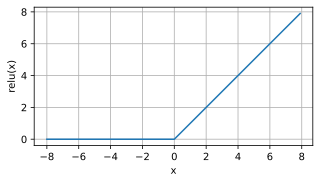

In [ ]:
%matplotlib inline
import torch
from d2l import torch as d2l

x=torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y=torch.relu(x)
d2l.plot(x.detach(), y.detach(), 'x', 'relu(x)', figsize=(5, 2.5))


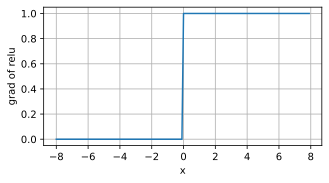

In [ ]:
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of relu', figsize=(5, 2.5))

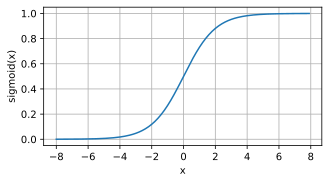

In [ ]:
y=torch.sigmoid(x)
d2l.plot(x.detach(), y.detach(), 'x', 'sigmoid(x)', figsize=(5, 2.5))

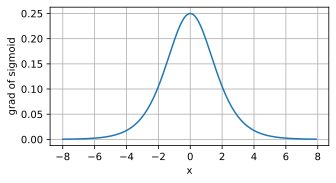

In [ ]:
x.grad.data.zero_()
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of sigmoid', figsize=(5, 2.5))

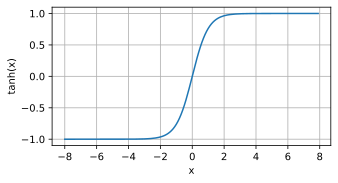

In [ ]:
y=torch.tanh(x)
d2l.plot(x.detach(), y.detach(), 'x', 'tanh(x)', figsize=(5, 2.5))

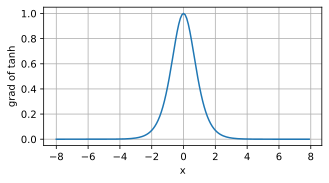

In [ ]:
x.grad.zero_()
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of tanh', figsize=(5, 2.5))

## 4.2 multiplayer proecptron implementation from scratch

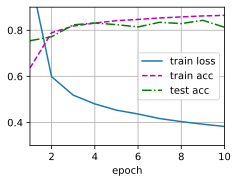

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l

batch_size=256
train_iter, test_iter=d2l.load_data_fashion_mnist(batch_size)

num_inputs, num_outputs, num_hiddens=784, 10, 256

W1=nn.Parameter(torch.randn(num_inputs, num_hiddens, requires_grad=True)*0.01)
b1=nn.Parameter(torch.zeros(num_hiddens, requires_grad=True))
W2=nn.Parameter(torch.randn(num_hiddens, num_outputs, requires_grad=True)*0.01)
b2=nn.Parameter(torch.zeros(num_outputs, requires_grad=True))

params=[W1, b1, W2, b2]

def relu(X):
  a=torch.zeros_like(X)
  return torch.max(X, a)

def net(X):
  X=X.reshape((-1, num_inputs))
  H=relu(X@W1+b1)
  return (H@W2+b2)

loss=nn.CrossEntropyLoss(reduction='none')

num_epochs, lr=10, 0.1
updater=torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, updater)

## 4.3 concise implementation of multilayer perceptron

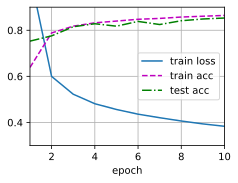

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l

net=nn.Sequential(nn.Flatten(),
                  nn.Linear(784, 256),
                  nn.ReLU(),
                  nn.Linear(256, 10))

def init_weights(m):
  if type(m)==nn.Linear:
    nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)

batch_size, lr, num_epochs=256, 0.1, 10
loss=nn.CrossEntropyLoss(reduction='none')
trainer=torch.optim.SGD(net.parameters(), lr=lr)

train_iter, test_iter=d2l.load_data_fashion_mnist(batch_size)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

## 4.4 multinomial regression

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

max_degree=20
n_train, n_test=100, 100
true_w=np.zeros(max_degree)
true_w[0:4]=np.array([5, 1.2, -3.4, 5.6])

features=np.random.normal(size=(n_train+n_test, 1))
np.random.shuffle(features)
poly_features=np.power(features, np.arange(max_degree).reshape(1, -1))
for i in range(max_degree):
  poly_features[:, i]/=math.gamma(i+1)

labels=np.dot(poly_features, true_w)
labels+=np.random.normal(scale=0.1, size=labels.shape)

true_w, features, poly_features, labels=[torch.tensor(x, dtype=torch.float32) for x in [true_w, features, poly_features, labels]]

features[:2], poly_features[:2, :], labels[:2]

(tensor([[0.4620],
         [1.6272]]),
 tensor([[1.0000e+00, 4.6202e-01, 1.0673e-01, 1.6438e-02, 1.8987e-03, 1.7545e-04,
          1.3510e-05, 8.9171e-07, 5.1499e-08, 2.6437e-09, 1.2215e-10, 5.1305e-12,
          1.9753e-13, 7.0204e-15, 2.3168e-16, 7.1363e-18, 2.0607e-19, 5.6006e-21,
          1.4376e-22, 3.4957e-24],
         [1.0000e+00, 1.6272e+00, 1.3239e+00, 7.1809e-01, 2.9212e-01, 9.5068e-02,
          2.5783e-02, 5.9934e-03, 1.2191e-03, 2.2041e-04, 3.5865e-05, 5.3055e-06,
          7.1943e-07, 9.0050e-08, 1.0466e-08, 1.1354e-09, 1.1547e-10, 1.1053e-11,
          9.9918e-13, 8.5572e-14]]),
 tensor([5.2331, 6.4990]))

In [ ]:
def evaluate_loss(net, data_iter, loss):
  metric=d2l.Accumulator(2);
  for X, y in data_iter:
    out=net(X)
    y=y.reshape(out.shape)
    l=loss(out, y)
    metric.add(l.sum(), l.numel())
  return metric[0]/metric[1]

def train(train_features, test_features, train_labels, test_labels, num_epochs=400):
  loss=nn.MSELoss(reduction='none')
  input_shape=train_features.shape[-1]
  net=nn.Sequential(nn.Linear(input_shape, 1, bias=False))

  batch_size=min(10, train_labels.shape[0])
  train_iter=d2l.load_array((train_features, train_labels.reshape(-1, 1)), batch_size)
  test_iter=d2l.load_array((test_features, test_labels.reshape(-1, 1)), batch_size, is_train=False)
  trainer=torch.optim.SGD(net.parameters(), lr=0.01)

  animator=d2l.Animator(xlabel='epoch', ylabel='loss', yscale='log', xlim=[1, num_epochs], ylim=[1e-3, 1e2], legend=['train', 'test'])

  for epoch in range(num_epochs):
    d2l.train_epoch_ch3(net, train_iter, loss, trainer)
    if epoch==0 or (epoch+1)%20==0:
      animator.add(epoch+1, (evaluate_loss(net, train_iter, loss), evaluate_loss(net, test_iter, loss)))
  print('weight:', net[0].weight.data.numpy())

weight: [[ 4.9915037  1.2471821 -3.3973987  5.5303726]]


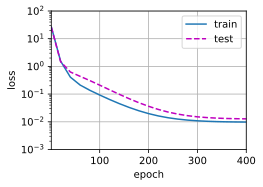

In [ ]:
train(poly_features[:n_train, :4], poly_features[n_train:, :4], labels[:n_train], labels[n_train:])

weight: [[3.1706042 4.903646 ]]


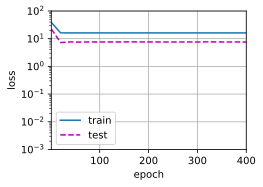

In [ ]:
train(poly_features[:n_train, :2], poly_features[n_train:, :2], labels[:n_train], labels[n_train:])

weight: [[ 4.971136    1.2656677  -3.241082    5.204527   -0.3926567   1.1018784
  -0.06870726  0.18911807  0.18522114 -0.18599044  0.11391872  0.04056612
  -0.10330158  0.16099617  0.17658895  0.07188766  0.10821164  0.20112565
  -0.1998174   0.01206645]]


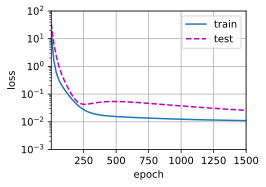

In [ ]:
train(poly_features[:n_train, :], poly_features[n_train:, :], labels[:n_train], labels[n_train:], num_epochs=1500)